# Proyecto Aplicativo 3 – Clasificación con redes neuronales feed-forward
## Dataset *Adult (Census Income)* – UCI Machine Learning Repository

**Curso:** Introducción a la Inteligencia Artificial · **Profesor:** Palacio Niño
**Equipo:** Samuel Daza, Nicolás Parra, Thomas López, Samuel Velandia

**Objetivo.** Predecir si una persona gana más de 50 000 USD al año (`income = >50K`) a partir de
sus atributos sociodemográficos del censo de EE. UU. de 1994, comparando tres arquitecturas
*feed-forward*: un **perceptrón simple**, un **MLP con una capa oculta** (tantas neuronas como
entradas) y un **MLP con dos capas ocultas de 2 neuronas**.

Toda la lógica vive en el paquete `src/clasificacion_adult/`; este cuaderno lo importa y narra
cada decisión. Las figuras (200 dpi) y tablas de `resultados/` las genera
`python main.py todo` con las mismas funciones; el cuaderno solo las muestra.

In [1]:
# Requiere el paquete instalado: pip install -r requirements.txt (incluye `-e .`)
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from clasificacion_adult import config as cfg
from clasificacion_adult import datos as dat
from clasificacion_adult import eda
from clasificacion_adult import evaluacion as ev
from clasificacion_adult import experimentos as exp
from clasificacion_adult import modelos as mod
from clasificacion_adult import preprocesamiento as prep

%matplotlib inline
eda.configurar_estilo()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("Semilla global:", cfg.SEMILLA)

Semilla global: 42


## 1. Descripción del problema y de los datos

El dataset *Adult* (Kohavi y Becker, 1996) proviene del censo de EE. UU. de 1994. UCI lo
distribuye en dos archivos: `adult.data` (32 561 filas) y `adult.test` (16 281 filas). Como
nosotros mismos definimos las particiones (sección 4), **los unimos** en un solo conjunto.

Detalles de lectura (implementados en `datos.cargar_datos`):

* Los archivos no tienen cabecera y los valores van separados por `", "` → `header=None`,
  `skipinitialspace=True`.
* Los faltantes están codificados como `?` → `na_values='?'`.
* La primera línea de `adult.test` es `|1x3 Cross validator` → `skiprows=1`.
* En `adult.test` las etiquetas terminan en punto (`<=50K.`), que se elimina para unificarlas.

Si los archivos no están en `data/raw/`, el paquete los descarga automáticamente.

In [2]:
crudos = dat.cargar_datos()
print(f"Filas: {crudos.shape[0]:,} | Columnas: {crudos.shape[1]}")
crudos.head()

Filas: 48,842 | Columnas: 15


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


**Variables.** 6 numéricas (`age`, `fnlwgt`, `education_num`, `capital_gain`, `capital_loss`,
`hours_per_week`), 8 categóricas (`workclass`, `education`, `marital_status`, `occupation`,
`relationship`, `race`, `sex`, `native_country`) y el objetivo binario `income`, que
codificamos como **y = 1 si `>50K`** (clase positiva, minoritaria).

## 2. Análisis exploratorio de datos (EDA)

### 2.1 Tipos, nulos y estadísticas descriptivas

In [3]:
display(eda.resumen_tipos(crudos))
eda.estadisticas_descriptivas(crudos)

,tipo,nulos,pct_nulos,unicos
age,int64,0,0.00,74
workclass,str,2799,5.73,8
fnlwgt,int64,0,0.00,28523
education,str,0,0.00,16
education_num,int64,0,0.00,16
marital_status,str,0,0.00,7
occupation,str,2809,5.75,14
relationship,str,0,0.00,6
race,str,0,0.00,5
sex,str,0,0.00,2


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0
education_num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0


* Solo tres columnas tienen nulos: `workclass`, `occupation` y `native_country`.
* `capital_gain` y `capital_loss` tienen mediana 0 y máximos muy altos (99 999 es un tope
  de codificación del censo): distribuciones extremadamente asimétricas.
* `fnlwgt` tiene una escala enorme (decenas de miles a millones): es el peso muestral del censo.

### 2.2 Distribución de la clase objetivo

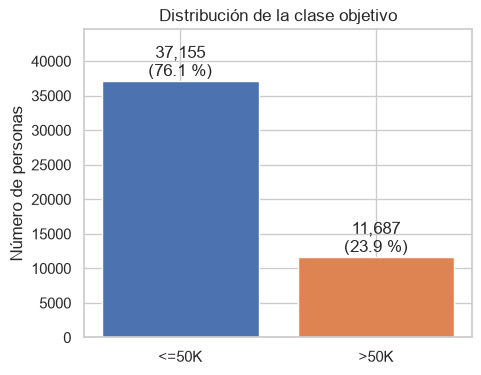

,conteo,porcentaje
income,,
<=50K,37155,76.07
>50K,11687,23.93


In [4]:
clases = eda.distribucion_clases(crudos)
eda.grafico_distribucion_clases(clases)
plt.show()
clases

El problema está **desbalanceado**: ~76 % `<=50K` frente a ~24 % `>50K`. Un clasificador
trivial que siempre responde `<=50K` ya obtiene ~76 % de accuracy, por eso en la sección 6
usamos métricas centradas en la clase minoritaria.

### 2.3 Variables numéricas por clase

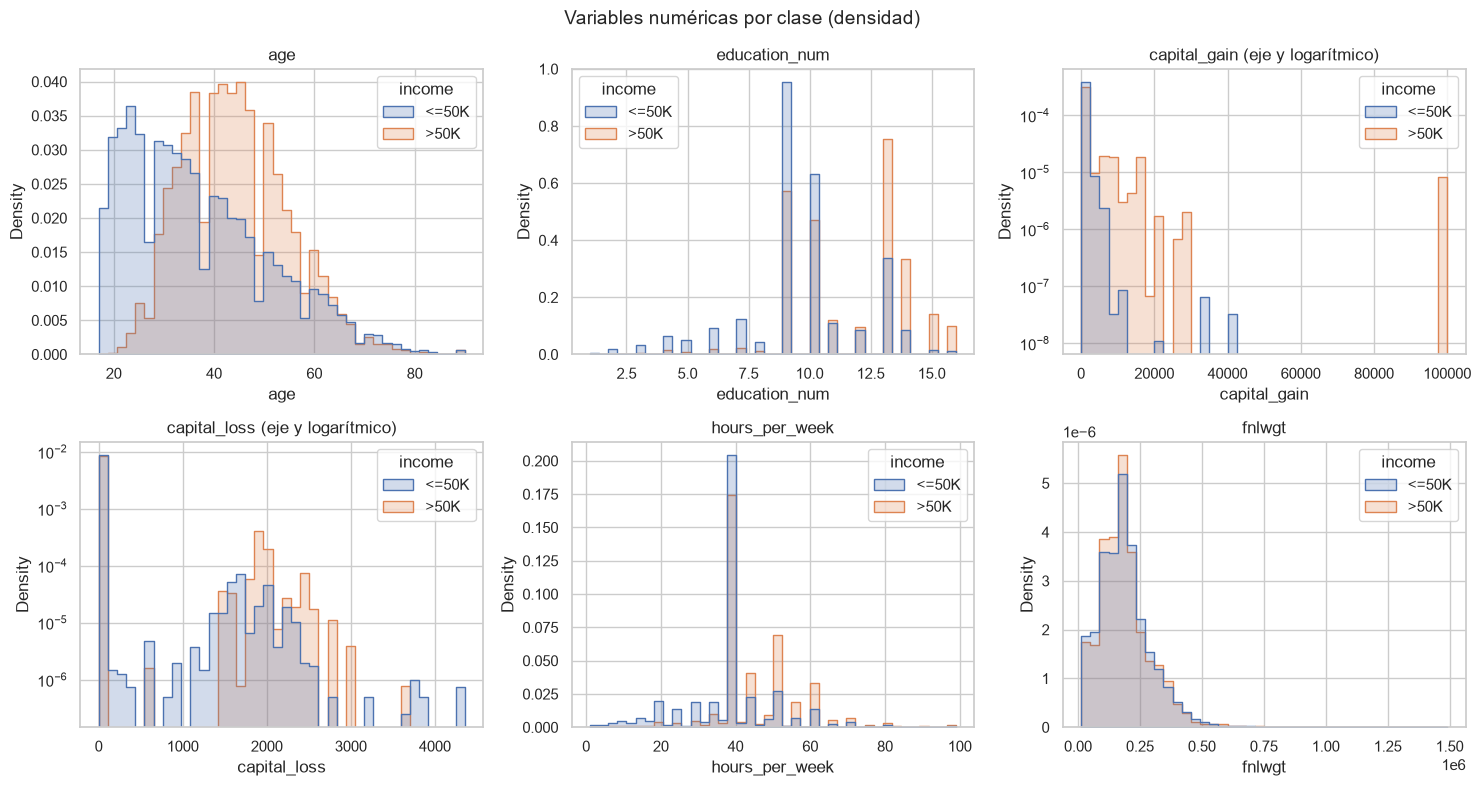

In [5]:
eda.histogramas_numericas(crudos);

* `age`: las personas con `>50K` se concentran entre 35 y 55 años; los muy jóvenes casi nunca
  superan el umbral.
* `education_num` y `hours_per_week`: valores altos se asocian claramente con `>50K`.
* `capital_gain` / `capital_loss`: casi todo es 0, pero tener ganancias de capital distintas
  de 0 es mucho más frecuente en la clase `>50K` (eje y en escala log).
* `fnlwgt`: las dos distribuciones prácticamente se superponen → poca información.

### 2.4 Variables categóricas y tasa de `>50K`

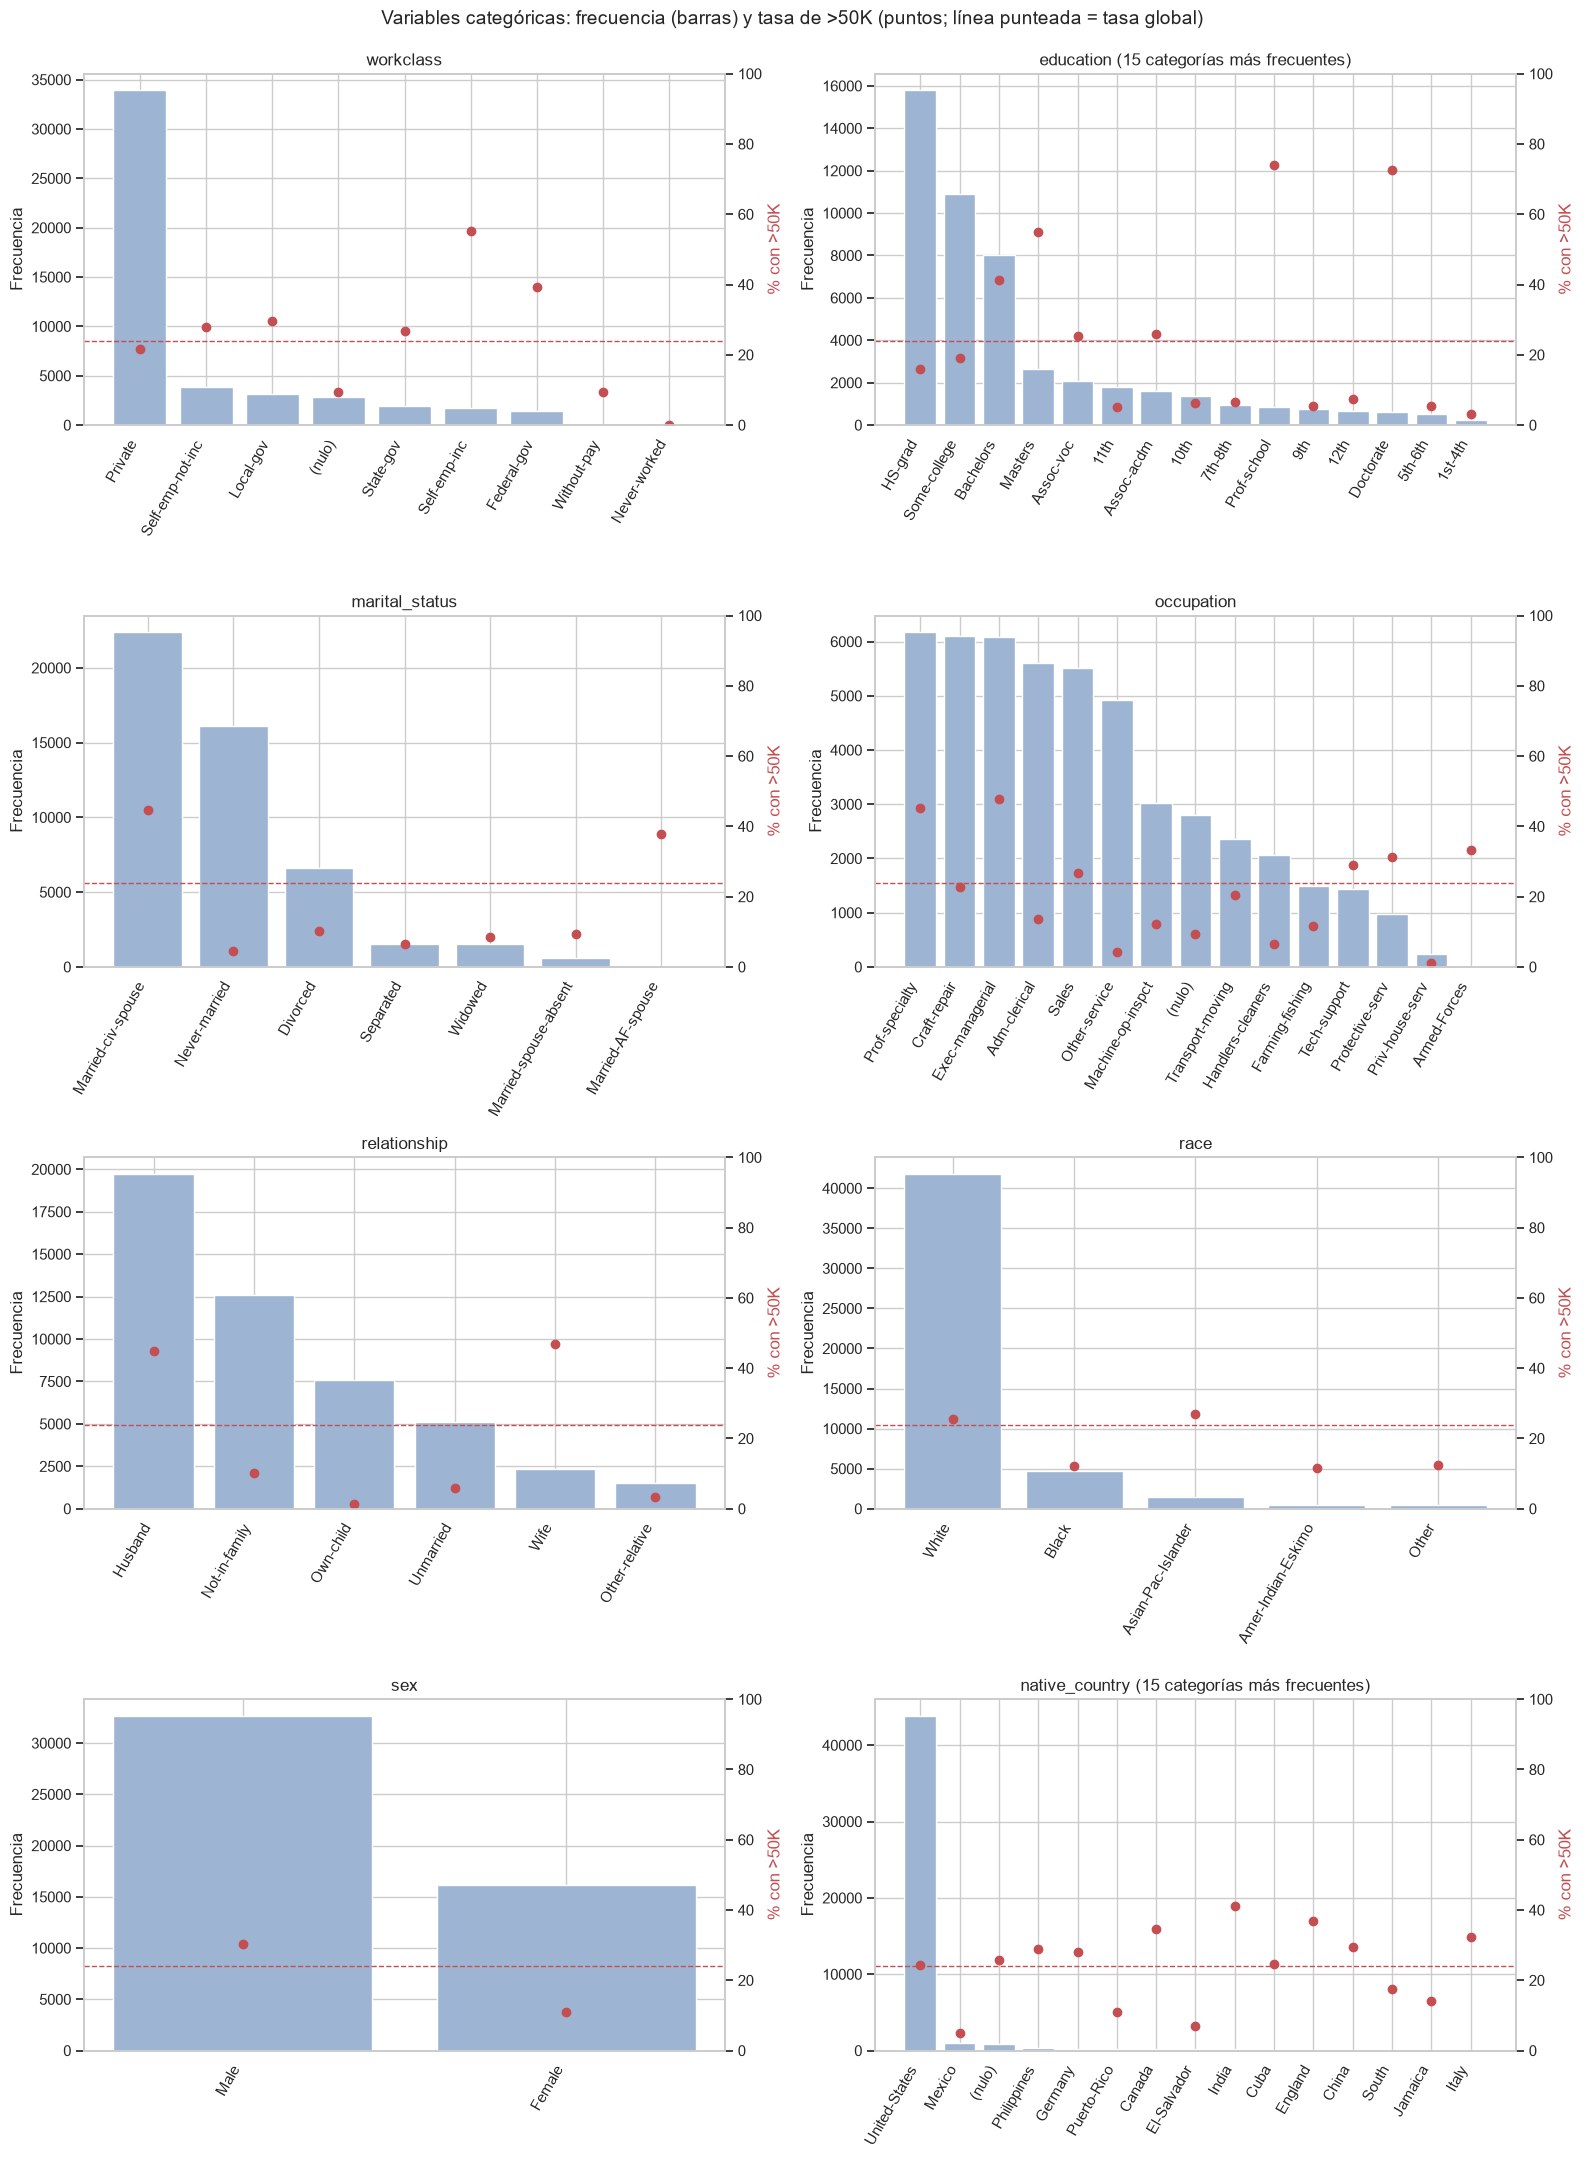

In [6]:
eda.barras_categoricas(crudos);

Barras = frecuencia de cada categoría; puntos rojos = porcentaje de `>50K` dentro de ella;
línea punteada = tasa global (~24 %). Destacan `marital_status = Married-civ-spouse` y
`relationship = Husband/Wife` (tasas cercanas al 45 %), las ocupaciones
`Exec-managerial` y `Prof-specialty`, y la educación universitaria. La categoría
`(nulo)` de `workclass`/`occupation` tiene una tasa muy por debajo de la global.

### 2.5 Atípicos (diagramas de caja)

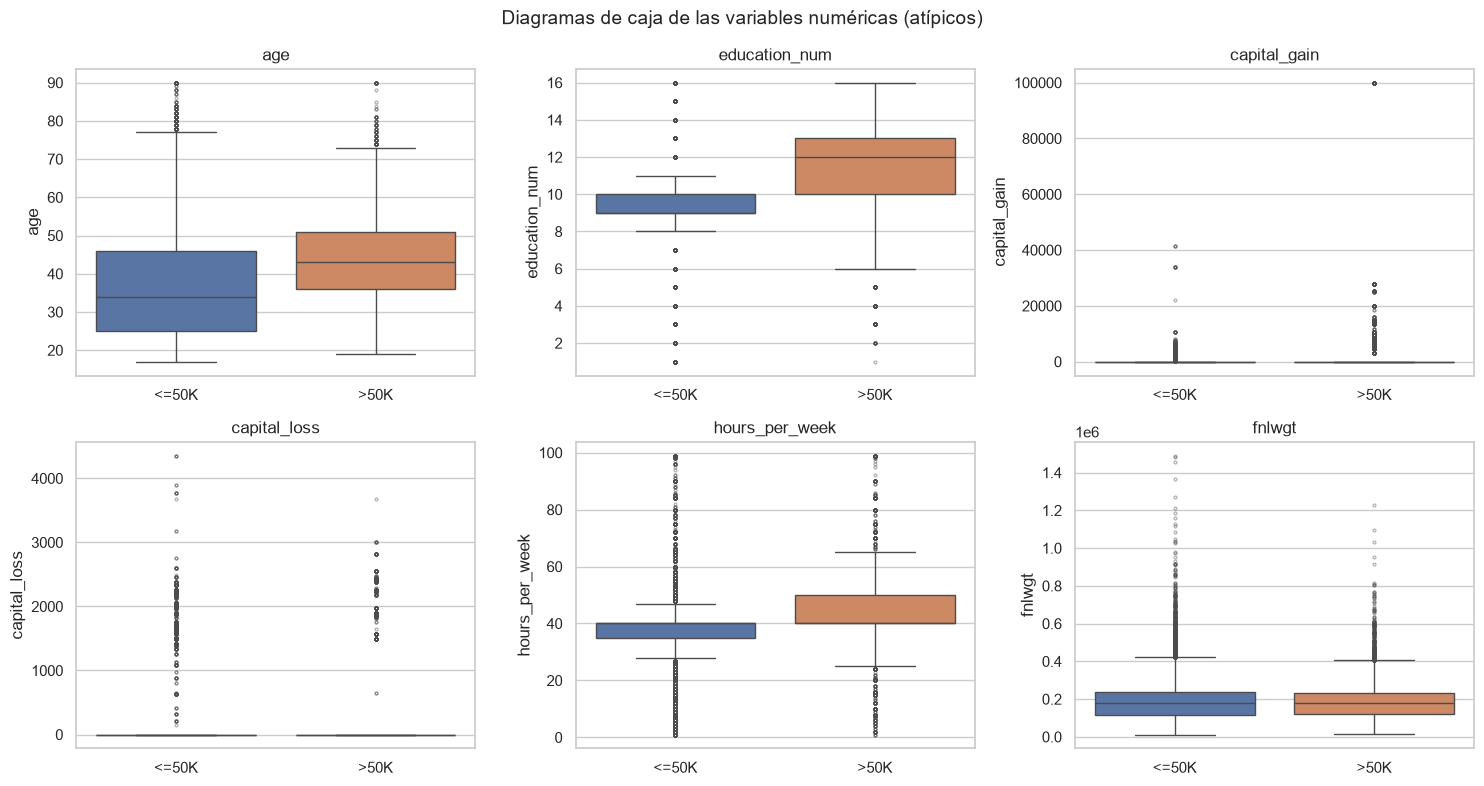

In [7]:
eda.boxplots_numericas(crudos);

Hay muchos puntos fuera de los bigotes en `capital_gain`, `capital_loss`, `hours_per_week`
y `fnlwgt`. Los cuantificamos con la regla IQR en la sección 3.

### 2.6 Valores nulos

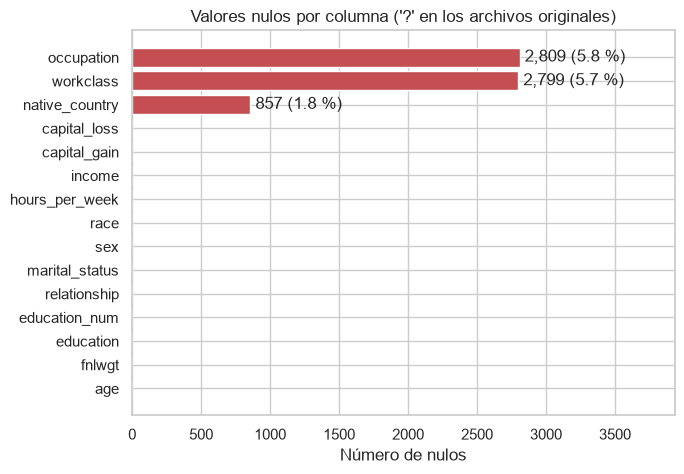

,nulos,tasa_>50K_con_nulo_%,tasa_>50K_sin_nulo_%
columna,,,
workclass,2799,9.47,24.81
occupation,2809,9.43,24.81
native_country,857,25.67,23.90


Filas con workclass Y occupation nulos a la vez: 2,799 de 2,799 nulos de workclass


In [8]:
eda.grafico_nulos(crudos)
plt.show()
display(eda.analisis_nulos(crudos))
juntos = (crudos["workclass"].isna() & crudos["occupation"].isna()).sum()
print(
    f"Filas con workclass Y occupation nulos a la vez: {juntos:,} "
    f"de {crudos['workclass'].isna().sum():,} nulos de workclass"
)

Los nulos **no son aleatorios**: `workclass` y `occupation` faltan casi siempre juntos (personas
que no reportaron empleo: jubilados, desempleados, etc.), y en esas filas la tasa de `>50K` es
de ~9 % frente a ~25 % en el resto. La ausencia es, en sí misma, información útil. En
`native_country` la tasa con nulo (~26 %) es similar a la global, así que ahí imputar
`"Desconocido"` es simplemente una forma neutra de conservar las filas.

### 2.7 Correlación (Pearson) y V de Cramér

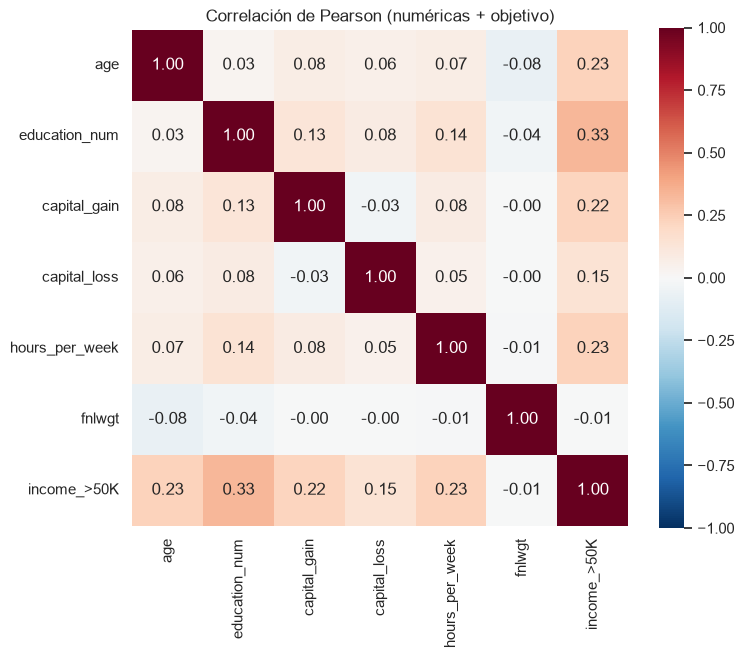

In [9]:
eda.grafico_correlacion(eda.correlacion_pearson(crudos));

`fnlwgt` tiene correlación ≈ 0 con el objetivo (y con todo lo demás). Las numéricas más
asociadas con `>50K` son `education_num`, `age`, `hours_per_week` y `capital_gain`. Entre las
numéricas no hay colinealidad fuerte (todas |r| < 0.2), así que no hay que eliminar ninguna por
redundancia lineal.

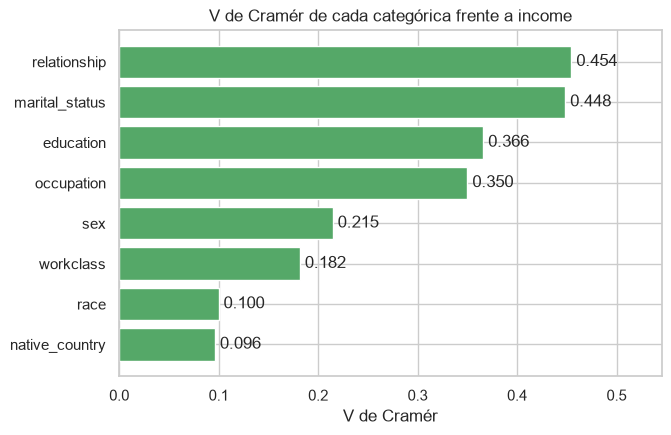

relationship      0.454
marital_status    0.448
education         0.366
occupation        0.350
sex               0.215
workclass         0.182
race              0.100
native_country    0.096
Name: V_de_Cramer, dtype: float64

In [10]:
v_cramer = eda.v_cramer_objetivo(crudos)
eda.grafico_v_cramer(v_cramer)
plt.show()
v_cramer.round(3)

`relationship` y `marital_status` son las categóricas más asociadas con el ingreso
(V ≈ 0.45), seguidas de `education` y `occupation`. `race` y `native_country` aportan poco.

Finalmente, verificamos que `education` y `education_num` son la misma información:

In [11]:
eda.redundancia_education(crudos)

,valores_distintos,education_num
education,,
Preschool,1,1
1st-4th,1,2
5th-6th,1,3
7th-8th,1,4
9th,1,5
10th,1,6
11th,1,7
12th,1,8
HS-grad,1,9


Cada nivel de `education` corresponde a **un único** valor de `education_num` (columna
`valores_distintos` = 1 en todas las filas): la relación es 1 a 1.

## 3. Preprocesamiento

Los pasos se aplican **en este orden**. Los pasos 1–2 no aprenden nada de los datos (no hay fuga
al hacerlos antes de partir); los pasos 3–7 viven dentro de un `ColumnTransformer` en un
`Pipeline`, que se ajusta **solo con el conjunto de entrenamiento**.

### 3.1 Duplicados exactos

In [12]:
print("Filas duplicadas exactas:", crudos.duplicated().sum())
limpios = dat.limpiar_datos(crudos)
print(f"Filas tras quitar duplicados: {len(limpios):,}")
print("Columnas finales:", list(limpios.columns))

Filas duplicadas exactas: 52
Filas tras quitar duplicados: 48,790
Columnas finales: ['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


Quitamos las 52 filas duplicadas para no darles doble peso y evitar que una misma persona
aparezca a la vez en train y en test (eso inflaría las métricas).

### 3.2 Eliminación de `fnlwgt` y `education`

* **`fnlwgt`** (*final weight*) es el número de personas de la población que representa cada
  registro según el diseño muestral del censo. No es un atributo de la persona y su correlación
  con el objetivo es ≈ 0 (sección 2.7).
* **`education`** es redundante 1:1 con `education_num` (sección 2.7). Conservamos la versión
  numérica porque es ordinal (1 = Preschool … 16 = Doctorate) y aporta una sola entrada a la
  red en lugar de 16 columnas *dummy*.

### 3.3 Valores nulos → categoría `"Desconocido"`

Imputamos `workclass`, `occupation` y `native_country` con la categoría explícita
`"Desconocido"` (`SimpleImputer(strategy="constant")`). **No eliminamos filas** porque los nulos
no son aleatorios (sección 2.6): borrar esas ~2 800 personas quitaría un subgrupo con
características propias y sesgaría el modelo, mientras que la categoría `"Desconocido"` deja que
la red aprenda que "no reportar ocupación" se asocia con menor ingreso.

### 3.4 `native_country`: agrupar países poco frecuentes

In [13]:
frec = limpios["native_country"].fillna(cfg.VALOR_NULO).value_counts(normalize=True)
print(f"Países distintos: {frec.size}")
print(f"Países con frecuencia >= {cfg.UMBRAL_FRECUENCIA_PAIS:.0%}:")
print((frec[frec >= cfg.UMBRAL_FRECUENCIA_PAIS] * 100).round(2).to_string())

Países distintos: 42
Países con frecuencia >= 1%:
native_country
United-States    89.76
Mexico            1.93
Desconocido       1.75


Más del 89 % son de `United-States`; 39 países tienen menos del 1 % cada uno. Codificarlos uno a
uno crearía columnas casi vacías (ruido y riesgo de sobreajuste), así que los agrupamos en
`"Otro"`. El transformador `AgrupadorCategoriasRaras` **aprende las frecuencias solo con
train**, y cualquier país no visto en entrenamiento también cae en `"Otro"`.

### 3.5 Atípicos: detección con IQR (sin eliminarlos)

In [14]:
prep.detectar_atipicos_iqr(limpios)

,Q1,Q3,IQR,limite_inferior,limite_superior,n_atipicos,pct_atipicos,pct_>50K_en_atipicos
variable,,,,,,,,
age,28.0,48.0,20.0,-2.0,78.0,215,0.44,17.67
education_num,9.0,12.0,3.0,4.5,16.5,1787,3.66,5.48
capital_gain,0.0,0.0,0.0,0.0,0.0,4035,8.27,61.73
capital_loss,0.0,0.0,0.0,0.0,0.0,2282,4.68,50.13
hours_per_week,40.0,45.0,5.0,32.5,52.5,13486,27.64,20.18


Regla de Tukey: es atípico todo valor fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR].

**Decisión: no los eliminamos.** Son valores reales (personas de 90 años, que trabajan 99 horas o
que tuvieron ganancias de capital), no errores de captura. Además, la última columna muestra que
el 62 % de los atípicos de `capital_gain` y el 50 % de los de `capital_loss` son de la clase
`>50K` (frente al 24 % global): eliminarlos borraría justamente ejemplos de la clase minoritaria
que queremos detectar. Eliminar todos los atípicos detectados quitaría además más de un tercio
de los datos (solo `hours_per_week` marca el 28 %). En `capital_gain`/`capital_loss` el IQR vale
0 (más del 90 % son ceros), así que *cualquier* valor distinto de 0 se marca como atípico.

En lugar de borrar, **reducimos su influencia** con `log1p` en las variables de capital:

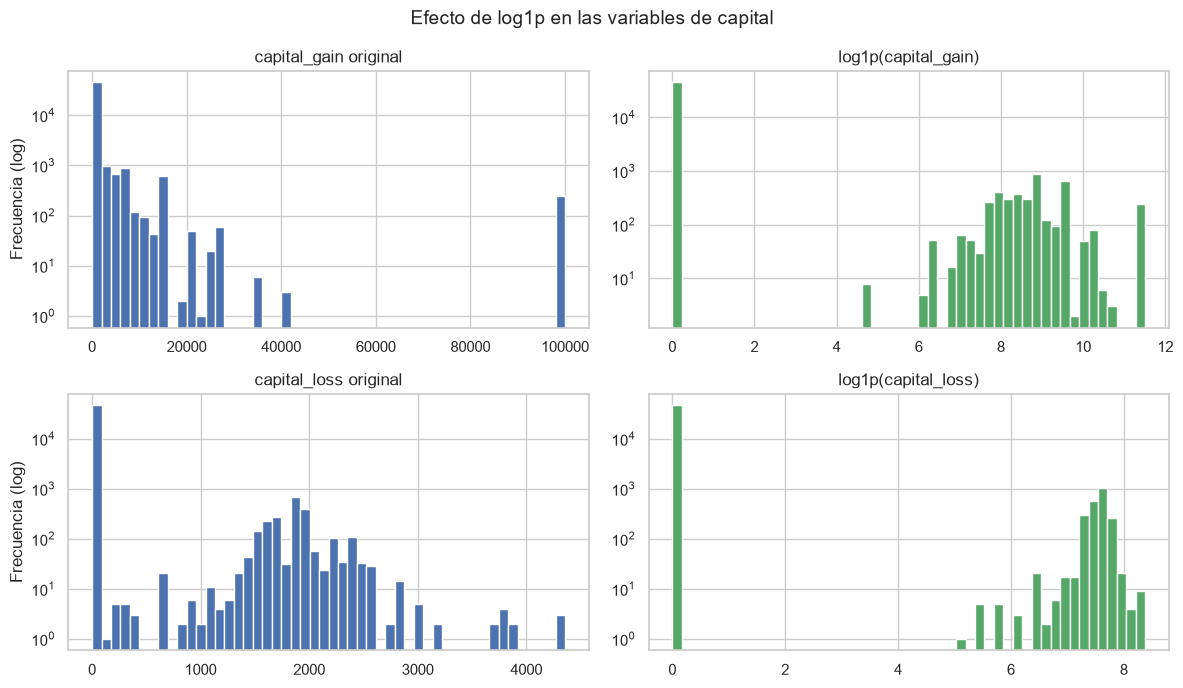

In [15]:
prep.grafico_log1p(limpios);

`log1p(x) = log(1 + x)` conserva el 0 como 0 y comprime la cola (99 999 → ≈ 11.5), de modo que
un solo valor extremo ya no domina el gradiente de la red.

### 3.6 Escalado y codificación

* **Numéricas** (`age`, `education_num`, `capital_gain`, `capital_loss`, `hours_per_week`) →
  `StandardScaler` (media 0, desviación 1). Las redes entrenadas con gradiente convergen mucho
  mejor cuando las entradas están en la misma escala.
* **Categóricas** → `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`: dumificación
  completa (una columna por categoría). Las categorías son nominales, así que no deben
  codificarse con enteros que impongan un orden inexistente.

### 3.7 El `ColumnTransformer` completo

In [16]:
preprocesador = prep.construir_preprocesador()
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## 4. Particiones

### 4.1 Partición principal: 80 / 20 estratificada

Usamos `train_test_split(test_size=0.2, stratify=y, random_state=42)`. La estratificación
garantiza la misma proporción de `>50K` en ambos conjuntos, lo que es importante con clases
desbalanceadas. El conjunto de prueba **no se toca** hasta la evaluación final; el *early
stopping* de los MLP reserva internamente un 10 % de train como validación.

In [17]:
X, y = dat.separar_x_y(limpios)
X_train, X_test, y_train, y_test = exp.dividir(X, y)
print(f"Train: {len(X_train):,} filas | Test: {len(X_test):,} filas")
proporciones_clase = pd.DataFrame(
    {"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}
)
proporciones_clase.rename(index={0: cfg.CLASE_NEGATIVA, 1: cfg.CLASE_POSITIVA}).round(4)

Train: 39,032 filas | Test: 9,758 filas


,train,test
y,,
<=50K,0.7606,0.7606
>50K,0.2394,0.2394


Ajustamos el preprocesador **solo con `X_train`** y aplicamos la transformación a ambos
conjuntos. Así, la media y desviación del escalador, las categorías del one-hot y los países
frecuentes provienen exclusivamente de entrenamiento (sin fuga de información del test).

In [18]:
preprocesador.fit(X_train)
Xt_train = preprocesador.transform(X_train)
Xt_test = preprocesador.transform(X_test)
nombres = preprocesador.get_feature_names_out()
n_entradas = len(nombres)
print("Forma de X_train transformado:", Xt_train.shape)
print("Forma de X_test transformado: ", Xt_test.shape)
print("Nulos tras el preprocesamiento:", int(np.isnan(Xt_train).sum() + np.isnan(Xt_test).sum()))
print("Número de entradas de la red:", n_entradas)

Forma de X_train transformado: (39032, 53)
Forma de X_test transformado:  (9758, 53)
Nulos tras el preprocesamiento: 0
Número de entradas de la red: 53


In [19]:
bloques = pd.Series([n.split("__")[0] for n in nombres]).value_counts()
print(bloques.to_string(), "\n")
print(list(nombres))

cat     44
pais     4
num      3
log      2 

['num__age', 'num__education_num', 'num__hours_per_week', 'log__capital_gain', 'log__capital_loss', 'cat__workclass_Desconocido', 'cat__workclass_Federal-gov', 'cat__workclass_Local-gov', 'cat__workclass_Never-worked', 'cat__workclass_Private', 'cat__workclass_Self-emp-inc', 'cat__workclass_Self-emp-not-inc', 'cat__workclass_State-gov', 'cat__workclass_Without-pay', 'cat__marital_status_Divorced', 'cat__marital_status_Married-AF-spouse', 'cat__marital_status_Married-civ-spouse', 'cat__marital_status_Married-spouse-absent', 'cat__marital_status_Never-married', 'cat__marital_status_Separated', 'cat__marital_status_Widowed', 'cat__occupation_Adm-clerical', 'cat__occupation_Armed-Forces', 'cat__occupation_Craft-repair', 'cat__occupation_Desconocido', 'cat__occupation_Exec-managerial', 'cat__occupation_Farming-fishing', 'cat__occupation_Handlers-cleaners', 'cat__occupation_Machine-op-inspct', 'cat__occupation_Other-service', 'cat__occupation_Pri

Con estas decisiones obtenemos **53 entradas**: 5 numéricas + 48 *dummies*
(`workclass` 9, `marital_status` 7, `occupation` 15, `relationship` 6, `race` 5, `sex` 2 y
`native_country` 4: United-States, Mexico, Desconocido y Otro).

### 4.2 Experimento de proporciones

Para estudiar cómo influye la cantidad de datos de entrenamiento repetimos el entrenamiento con
train = 50, 60, 70, 80 y 90 % (test = el resto), cada uno con 5 semillas (0–4), siempre
estratificado. Los resultados están en la sección 6.5.

## 5. Modelos

Las tres arquitecturas son *feed-forward* y **todas sus neuronas tienen bias**:

| Modelo | Arquitectura | Detalles |
|---|---|---|
| Perceptrón | 53 → 1 | `Perceptron(fit_intercept=True, max_iter=1000, tol=1e-3)`; función escalón, regla de aprendizaje del perceptrón |
| MLP 1 capa oculta | 53 → **53** → 1 | n.º de neuronas ocultas = n.º de entradas, calculado dinámicamente |
| MLP 2 capas ocultas | 53 → 2 → 2 → 1 | `hidden_layer_sizes=(2, 2)` |

Ambos MLP: activación `relu`, optimizador `adam`, `learning_rate_init=0.001`, regularización L2
`alpha=1e-4`, `max_iter=300`, *early stopping* con 10 % de validación y paciencia de 10 épocas;
la neurona de salida es logística (sigmoide) y la pérdida es la entropía cruzada binaria.
`MLPClassifier` siempre incluye bias (`intercepts_`) en cada capa.

In [20]:
for nombre, modelo in mod.crear_modelos(n_entradas).items():
    print(f"{nombre}:\n  {modelo}\n")

Perceptrón:
  Perceptron(random_state=42)

MLP 1 capa oculta:
  MLPClassifier(early_stopping=True, hidden_layer_sizes=(53,), max_iter=300,
              random_state=42)

MLP 2 capas ocultas (2, 2):
  MLPClassifier(early_stopping=True, hidden_layer_sizes=(2, 2), max_iter=300,
              random_state=42)



### 5.1 Entrenamiento

`exp.entrenar_y_evaluar` encapsula cada modelo en `Pipeline([preprocesador, modelo])` (un
preprocesador nuevo por modelo, ajustado con train), lo entrena con la partición 80/20 y lo
evalúa en test. También entrena la línea base `DummyClassifier(strategy="most_frequent")`.

In [21]:
res = exp.entrenar_y_evaluar(X, y, guardar=False)
print("Entradas de la red:", res.n_entradas)
pd.Series(res.tiempos, name="segundos de entrenamiento").round(2)

Entradas de la red: 53


Línea base (siempre <=50K)    0.12
Perceptrón                    0.23
MLP 1 capa oculta             5.70
MLP 2 capas ocultas (2, 2)    2.03
Name: segundos de entrenamiento, dtype: float64

### 5.2 Evidencia de los pesos y del bias

Para cada modelo imprimimos la forma de las matrices de pesos (`coef_` / `coefs_`) y de los
vectores de bias (`intercept_` / `intercepts_`). Hay un vector de bias por cada capa, con una
componente por neurona.

In [22]:
for nombre in [mod.NOMBRE_PERCEPTRON, mod.NOMBRE_MLP_1, mod.NOMBRE_MLP_2]:
    modelo = res.pipelines[nombre].named_steps["modelo"]
    print(f"--- {nombre} ---")
    display(mod.describir_pesos(modelo))
    if hasattr(modelo, "coefs_"):
        print("  coefs_      :", [W.shape for W in modelo.coefs_])
        print("  intercepts_ :", [b.shape for b in modelo.intercepts_])
        print(f"  épocas entrenadas: {modelo.n_iter_}")
    else:
        print("  coef_      :", modelo.coef_.shape, "| intercept_ :", modelo.intercept_)
        print(f"  épocas entrenadas: {modelo.n_iter_}")

--- Perceptrón ---


,pesos (coef_),bias (intercept_)
capa,,
entrada -> salida,"(1, 53)","(1,)"


  coef_      : (1, 53) | intercept_ : [-6.]
  épocas entrenadas: 11
--- MLP 1 capa oculta ---


,pesos (coefs_),bias (intercepts_)
capa,,
0 -> 1,"(53, 53)","(53,)"
1 -> 2,"(53, 1)","(1,)"


  coefs_      : [(53, 53), (53, 1)]
  intercepts_ : [(53,), (1,)]
  épocas entrenadas: 36
--- MLP 2 capas ocultas (2, 2) ---


,pesos (coefs_),bias (intercepts_)
capa,,
0 -> 1,"(53, 2)","(2,)"
1 -> 2,"(2, 2)","(2,)"
2 -> 3,"(2, 1)","(1,)"


  coefs_      : [(53, 2), (2, 2), (2, 1)]
  intercepts_ : [(2,), (2,), (1,)]
  épocas entrenadas: 17


* Perceptrón: `coef_` de forma (1, 53) y un bias escalar.
* MLP 1 capa: (53, 53) + bias (53,) en la capa oculta y (53, 1) + bias (1,) en la salida.
* MLP 2 capas: (53, 2) → (2, 2) → (2, 1), con biases (2,), (2,) y (1,).

Número de parámetros entrenables: perceptrón 54; MLP (53) 53·53 + 53 + 53 + 1 = 2 916;
MLP (2, 2) 53·2 + 2 + 2·2 + 2 + 2 + 1 = 117.

## 6. Resultados

### 6.1 Métricas en el conjunto de prueba

Todas las métricas binarias (precisión, recall, F1) se calculan para la **clase positiva `>50K`**.
Añadimos macro-F1 (promedio del F1 de ambas clases), *balanced accuracy* (promedio del recall
de cada clase) y ROC-AUC (calculado con `predict_proba` en los MLP y con `decision_function`
—distancia al hiperplano— en el perceptrón, que no produce probabilidades).

In [23]:
metricas = res.metricas.copy()
metricas.round(4)

,accuracy,precision,recall,f1,macro_f1,balanced_accuracy,roc_auc,epocas,tiempo_s
modelo,,,,,,,,,
Línea base (siempre <=50K),0.7606,0.0000,0.0000,0.0000,0.4320,0.5000,0.5000,NaN,0.12
Perceptrón,0.7972,0.5600,0.7132,0.6274,0.7440,0.7684,0.8667,11.0,0.23
MLP 1 capa oculta,0.8565,0.7281,0.6396,0.6809,0.7942,0.7822,0.9136,36.0,5.70
"MLP 2 capas ocultas (2, 2)",0.7603,0.2000,0.0004,0.0009,0.4323,0.4999,0.4998,17.0,2.03


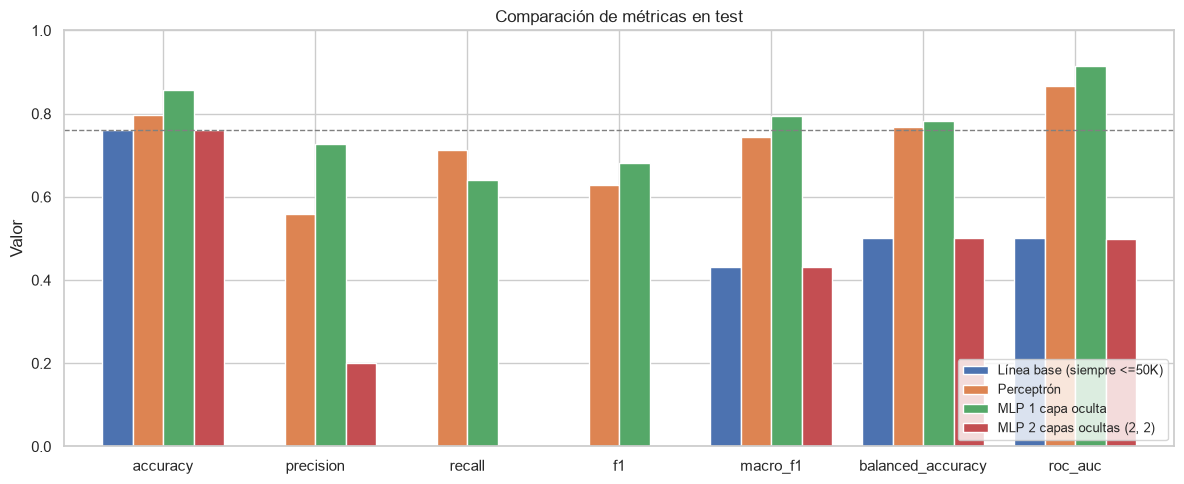

In [24]:
ev.grafico_comparacion_metricas(metricas, exp.NOMBRE_BASE);

### 6.2 Matrices de confusión

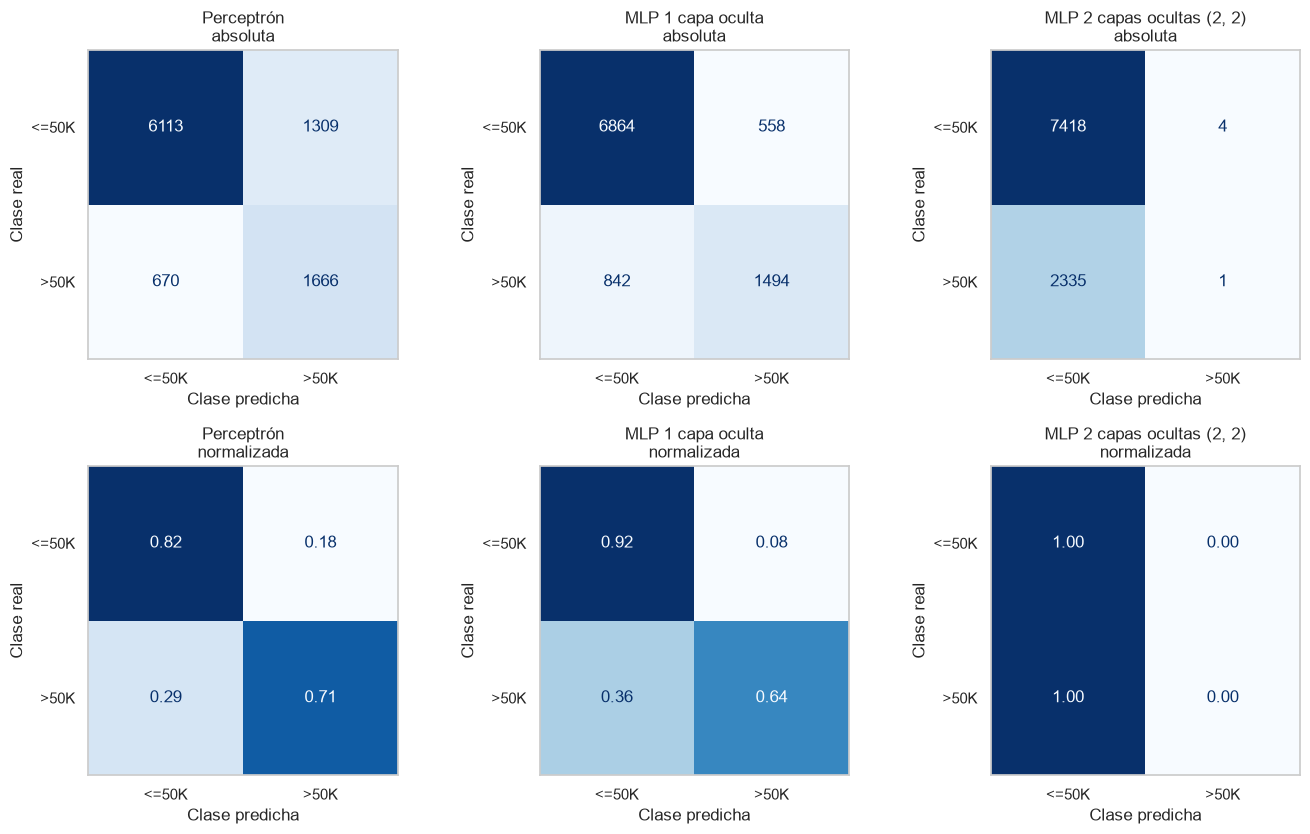

In [25]:
ev.grafico_matrices_confusion(res.y_test, {k: res.predicciones[k] for k in res.redes});

Fila superior: conteos; fila inferior: normalizada por la clase real (la diagonal es el recall
de cada clase). La celda inferior izquierda son los **falsos negativos**: personas con `>50K`
que el modelo clasificó como `<=50K`.

### 6.3 Curvas ROC y curvas de pérdida

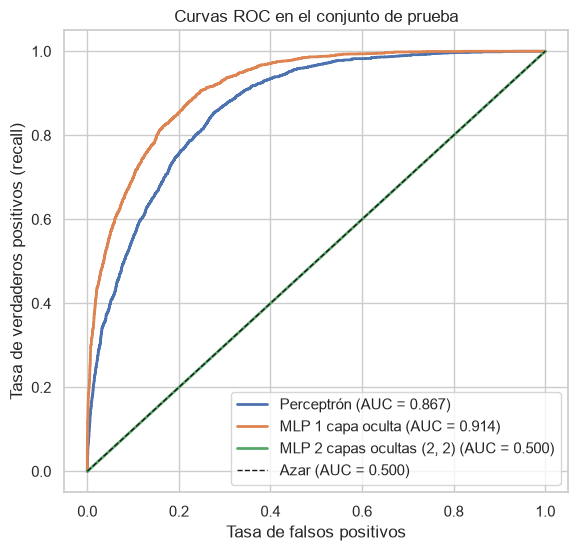

In [26]:
ev.grafico_roc(res.y_test, {k: res.scores[k] for k in res.redes});

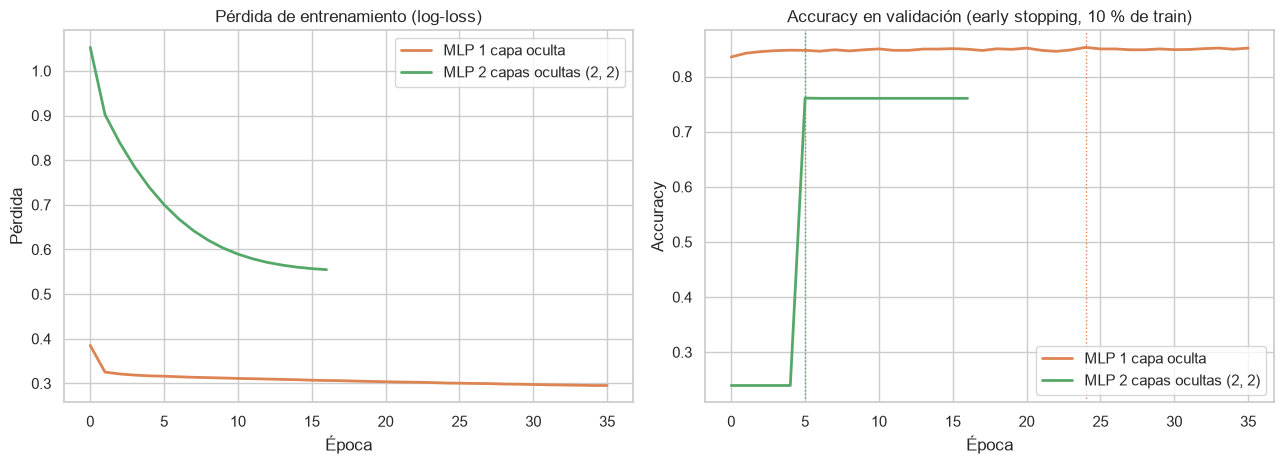

In [27]:
ev.grafico_curvas_perdida(res.mlps());

La curva de pérdida (izquierda) muestra la entropía cruzada en entrenamiento por época; la de la
derecha, el accuracy en el 10 % de validación que usa el *early stopping* (la línea punteada
marca la mejor época: el entrenamiento se detiene 10 épocas después sin mejora y se restauran
esos pesos).

### 6.4 Diagnóstico del MLP (2, 2): colapso a la clase mayoritaria

En la tabla de 6.1 el MLP con dos capas de 2 neuronas obtiene F1 ≈ 0 y AUC ≈ 0.5: **predice
siempre `<=50K`**, igual que la línea base. Revisamos qué pasó dentro de la red:

In [28]:
pipe_mlp2 = res.pipelines[mod.NOMBRE_MLP_2]
mlp2 = pipe_mlp2.named_steps["modelo"]
Xt_train_mlp2 = pipe_mlp2.named_steps["preprocesador"].transform(res.X_train)
print("Neuronas muertas por capa (semilla 42):", mod.neuronas_muertas(mlp2, Xt_train_mlp2))
print(f"Épocas: {mlp2.n_iter_} | pérdida final: {mlp2.loss_curve_[-1]:.4f}")
print(f"Log-loss del modelo constante (entropía a priori): {ev.entropia_a_priori(res.y_train):.4f}")
print(f"Fracción predicha como >50K en test: {pipe_mlp2.predict(res.X_test).mean():.4f}")

Neuronas muertas por capa (semilla 42): [0, 1]
Épocas: 17 | pérdida final: 0.5548
Log-loss del modelo constante (entropía a priori): 0.5504
Fracción predicha como >50K en test: 0.0005


Repetimos el entrenamiento del MLP (2, 2) con la semilla 42 y con las semillas 0–4 sobre la
misma partición 80/20 (`exp.diagnostico_semillas_mlp2`):

In [29]:
exp.diagnostico_semillas_mlp2(res, guardar=False)

,muertas_capa1,muertas_capa2,epocas,perdida_final,f1,roc_auc
semilla,,,,,,
42,0,1,17,0.5548,0.0009,0.4998
0,0,0,34,0.3255,0.6625,0.9039
1,0,0,32,0.3277,0.6671,0.9030
2,0,1,57,0.3271,0.6694,0.9057
3,0,0,21,0.3301,0.6573,0.9002
4,0,0,32,0.3351,0.6604,0.8996


**Interpretación del diagnóstico.** Con `random_state=42`, una de las dos neuronas de la segunda
capa oculta queda **muerta** (su preactivación ReLU es negativa para todos los ejemplos, así que
su salida y su gradiente son siempre 0) y la pérdida final queda en ≈ 0.555, prácticamente igual
a la entropía a priori (≈ 0.550): la red solo aprendió la proporción de clases. Con apenas 2
neuronas por capa no hay redundancia que compense una mala inicialización. Además, el *early
stopping* vigila el accuracy de validación, que se queda plano en ~76 % mientras la red está
estancada, de modo que detiene el entrenamiento a las pocas épocas. Con las semillas 0–4 la
**misma arquitectura sí aprende** (pérdida ≈ 0.33, F1 ≈ 0.66): el problema es de
inicialización/optimización, no de capacidad. Mantenemos la semilla 42 en la tabla principal
por reproducibilidad y transparencia, y el experimento de 6.5 (5 semillas) da una estimación más
representativa de esta arquitectura.

### Discusión: el desbalance y la elección de métricas

* **El accuracy engaña.** La línea base "siempre `<=50K`" ya obtiene ~76 % de accuracy sin
  detectar a una sola persona con `>50K` (recall = F1 = 0, balanced accuracy = 0.5). El MLP (2, 2)
  con semilla 42 empata con ella en accuracy y es inútil. Por eso priorizamos **F1, recall y
  balanced accuracy de la clase minoritaria**, además del ROC-AUC, que no depende del umbral.
* **MLP 1 capa oculta (53 neuronas)** es el mejor modelo: accuracy ≈ 0.857, F1 ≈ 0.68,
  balanced accuracy ≈ 0.78 y ROC-AUC ≈ 0.91. Es el más preciso (≈ 73 % de sus alertas `>50K`
  son correctas), aunque deja escapar ~36 % de los `>50K` (recall ≈ 0.64).
* **Perceptrón**: al ser un clasificador lineal con función escalón no puede modelar
  interacciones entre variables; su accuracy (≈ 0.80) es claramente inferior. Curiosamente, con
  esta semilla tiene el mayor recall (≈ 0.71) a costa de muchos falsos positivos (precisión
  ≈ 0.56). Como los datos no son linealmente separables, la regla del perceptrón nunca converge
  y el resultado depende mucho de en qué época se detiene (ver la alta desviación en 6.5).
* **Compromiso precisión–recall.** Los MLP usan umbral 0.5 sobre la probabilidad; con clases
  desbalanceadas ese umbral favorece a la clase mayoritaria. Si el objetivo fuera detectar más
  personas `>50K`, bastaría bajar el umbral (la curva ROC muestra que el MLP 1 capa domina a los
  demás en todos los umbrales) o usar pesos de clase.

### 6.5 Experimento de proporciones de entrenamiento

5 proporciones × 5 semillas × 3 modelos = 75 entrenamientos. La semilla controla tanto la
partición como la inicialización de la red, de modo que la desviación estándar refleja ambas
fuentes de variabilidad. (Esta celda tarda unos minutos.)

In [30]:
detalle, resumen = exp.experimento_proporciones(X, y, guardar=False, verbose=False)
resumen[["accuracy", "precision", "recall", "f1"]]

accuracy        precision           recall               f1
modelo                     proporcion_train                                                                    
MLP 1 capa oculta          0.5               0.8510 ± 0.0017  0.7262 ± 0.0153  0.6074 ± 0.0237  0.6611 ± 0.0085
                           0.6               0.8528 ± 0.0040  0.7292 ± 0.0132  0.6128 ± 0.0061  0.6659 ± 0.0073
                           0.7               0.8544 ± 0.0021  0.7295 ± 0.0085  0.6230 ± 0.0158  0.6719 ± 0.0075
                           0.8               0.8574 ± 0.0025  0.7446 ± 0.0109  0.6157 ± 0.0201  0.6738 ± 0.0096
                           0.9               0.8560 ± 0.0042  0.7368 ± 0.0160  0.6207 ± 0.0114  0.6737 ± 0.0081
MLP 2 capas ocultas (2, 2) 0.5               0.8448 ± 0.0017  0.7102 ± 0.0122  0.5951 ± 0.0257  0.6471 ± 0.0108
                           0.6               0.8468 ± 0.0032  0.7168 ± 0.0150  0.5966 ± 0.0274  0.6507 ± 0.0124
                           0.7               0.8465 ± 0.0022  0.7144 ± 0.0145  0.5989 ± 0.0257  0.6511 ± 0.0100
                           0.8               0.8470 ± 0.0036  0.7200 ± 0.0150  0.5912 ± 0.0217  0.6489 ± 0.0114
                           0.9               0.8450 ± 0.0063  0.7105 ± 0.0232  0.5964 ± 0.0248  0.6480 ± 0.0151
Perceptrón                 0.5               0.7555 ± 0.0127  0.4954 ± 0.0182  0.7078 ± 0.1405  0.5767 ± 0.0412
                           0.6               0.7917 ± 0.0109  0.5941 ± 0.0552  0.4429 ± 0.1164  0.4981 ± 0.0653
                           0.7               0.7939 ± 0.0232  0.5982 ± 0.0888  0.5264 ± 0.1966  0.5356 ± 0.0974
                           0.8               0.7687 ± 0.0369  0.5642 ± 0.1048  0.5465 ± 0.2680  0.5012 ± 0.1460
                           0.9               0.7986 ± 0.0198  0.5943 ± 0.0766  0.6351 ± 0.2014  0.5907 ± 0.0697

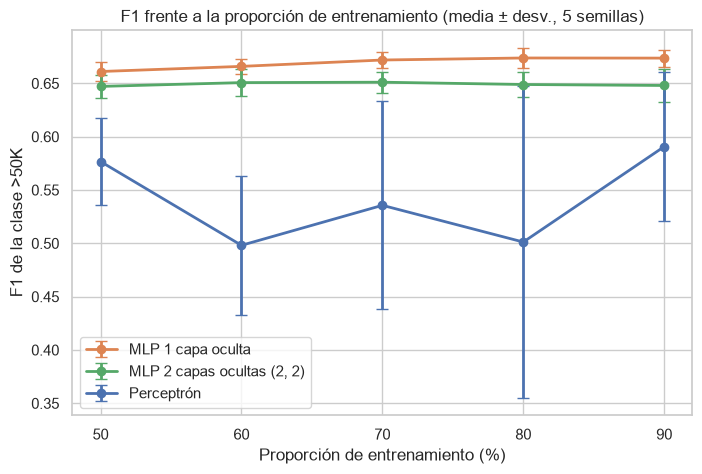

In [31]:
ev.grafico_proporciones(resumen);

**Análisis del experimento de proporciones.**

* **MLP 1 capa oculta**: el F1 crece levemente de ≈ 0.661 (50 % train) a ≈ 0.674 (80–90 %) y
  luego se estabiliza; la desviación entre semillas es pequeña (≈ 0.01). Con ~24 000 ejemplos de
  entrenamiento el modelo ya está cerca de su techo: más datos ayudan poco, y con 90 % el test
  es más pequeño y la estimación más ruidosa.
* **MLP (2, 2)**: F1 ≈ 0.65 en todas las proporciones, sin tendencia clara. Su capacidad
  (117 parámetros) es el límite, no la cantidad de datos. En las 25 corridas no se repitió el
  colapso de la semilla 42, lo que confirma que fue un caso de inicialización desafortunada.
* **Perceptrón**: F1 entre ≈ 0.50 y ≈ 0.59 con desviaciones de hasta ±0.15 y recall que oscila
  entre 0.44 y 0.71 de media (con desviación de hasta ±0.27). Más datos no lo estabilizan:
  como el problema no es linealmente separable, el perceptrón oscila y su solución final
  depende de la semilla más que de la proporción de entrenamiento.
* La proporción 80/20 usada en el experimento principal es un buen equilibrio: el rendimiento de
  las redes ya está estabilizado y el conjunto de prueba (~9 800 filas) es suficientemente grande
  para estimarlo con poca varianza.

## Conclusiones

1. **Preprocesamiento.** Quitamos 52 duplicados y dos columnas sin valor predictivo
   (`fnlwgt`) o redundantes (`education`); conservamos los nulos como categoría
   `"Desconocido"` porque su ausencia es informativa, y mantuvimos los atípicos (reales y
   concentrados en la clase `>50K`) suavizando el capital con `log1p`. Todo el preprocesamiento
   aprendido se ajusta solo con train dentro de un `Pipeline`, sin fuga de datos, y produce
   53 entradas.
2. **Mejor modelo: MLP con una capa oculta de 53 neuronas** (accuracy ≈ 0.86, F1 ≈ 0.68,
   ROC-AUC ≈ 0.91). La capa oculta le permite capturar relaciones no lineales que el perceptrón
   no puede representar.
3. **Arquitecturas muy estrechas son frágiles.** El MLP (2, 2) puede colapsar a la clase
   mayoritaria por neuronas ReLU muertas según la inicialización; cuando entrena bien
   (semillas 0–4) queda cerca del MLP grande (F1 ≈ 0.65–0.67), pero nunca lo supera.
4. **Con clases desbalanceadas el accuracy no basta**: un modelo inútil obtiene ~76 %. F1,
   recall, balanced accuracy y ROC-AUC de la clase minoritaria son las métricas adecuadas.
5. **Más datos ayudan poco a partir del 70–80 %**: las curvas de F1 frente a la proporción de
   entrenamiento se aplanan; la variabilidad entre semillas (sobre todo en el perceptrón)
   pesa más que la proporción elegida.

**Trabajo futuro:** ajustar el umbral de decisión o usar pesos de clase para subir el recall,
búsqueda de hiperparámetros con validación cruzada, e inicializaciones/activaciones que eviten
neuronas muertas (p. ej. *Leaky ReLU*).

Este cuaderno **no escribe archivos** (todas las llamadas usan `guardar=False`): las tablas y
figuras de `resultados/` las genera `python main.py todo` con exactamente el mismo código.

In [32]:
print("Archivos generados por main.py:")
for carpeta in (cfg.DIR_FIGURAS, cfg.DIR_TABLAS):
    for archivo in sorted(carpeta.iterdir()):
        print("  ", archivo.relative_to(cfg.RAIZ))

Archivos generados por main.py:
   resultados\figuras\colapso_inicializacion.png
   resultados\figuras\comparacion_metricas.png
   resultados\figuras\curvas_perdida_mlp.png
   resultados\figuras\curvas_roc.png
   resultados\figuras\eda_barras_categoricas.png
   resultados\figuras\eda_boxplots_numericas.png
   resultados\figuras\eda_correlacion_pearson.png
   resultados\figuras\eda_distribucion_clases.png
   resultados\figuras\eda_histogramas_numericas.png
   resultados\figuras\eda_nulos_por_columna.png
   resultados\figuras\eda_v_cramer.png
   resultados\figuras\matrices_confusion.png
   resultados\figuras\prep_log1p_capital.png
   resultados\figuras\proporciones_f1.png
   resultados\tablas\atipicos_iqr.csv
   resultados\tablas\colapso_inicializacion.csv
   resultados\tablas\diagnostico_mlp_2_2_semillas.csv
   resultados\tablas\eda_analisis_nulos.csv
   resultados\tablas\eda_correlacion_pearson.csv
   resultados\tablas\eda_distribucion_clases.csv
   resultados\tablas\eda_estadisticas_d